In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import FancyArrowPatch
import jax
import jax.numpy as jnp
from jax import jacfwd, jit

In [2]:
m = 1
g = 9.81
dt = 0.05

# Fixed point (hover)
x_fixed = np.array([[3.0], [3.0], [0.0], [0.0], [0.0], [0.0]])
u_fixed = np.array([[m * g], [0.0]]) 

def dynamics(x,u):
    J = 0.05 # Inertia

    # Constants
    k_x = 0.3 # Drag coefficient along body x-axis
    k_y = 0.3 # Drag coefficient along body y-axis
    k_theta = 0.02 # Drag coefficient for theta_dot

    # Extract info from x,u vectors
    theta = x[2, 0]
    x_dot = x[3, 0]
    y_dot = x[4, 0]
    theta_dot = x[5, 0]
    T = u[0, 0]
    tau = u[1, 0]

    # Calculate local velocities
    v_x = x_dot * jnp.cos(theta) + y_dot * jnp.sin(theta)
    v_y = -x_dot * jnp.sin(theta) + y_dot * jnp.cos(theta) 

    # Calculate drag forces
    f_x = -k_x * v_x * jnp.abs(v_x)
    f_y = -k_y * v_y * jnp.abs(v_y)
    f_theta = -k_theta * theta_dot
    
    # Global x-acceleration
    x_ddot = (1/m) * (-jnp.sin(theta) * (T + f_y) + jnp.cos(theta) * f_x)
    
    # Global y-acceleration
    y_ddot = (1/m) * (jnp.cos(theta) * (T + f_y) + jnp.sin(theta) * f_x) - g
    
    # Angular acceleration
    theta_ddot = (tau - f_theta) / J

    f = jnp.block([[x_dot], [y_dot], [theta_dot], [x_ddot], [y_ddot], [theta_ddot]])
    return f

In [3]:
# =====================================================
# 1. DISCRETIZATION
# =====================================================
def rk4(x, u, dt):
    f1 = dynamics(x, u)
    f2 = dynamics(x + f1 * (dt/2), u)
    f3 = dynamics(x + f2 * (dt/2), u)
    f4 = dynamics(x + f3 * dt, u)
    x_n = x + (dt/6) * (f1 + 2*f2 + 2*f3 + f4)

    return x_n

In [4]:
# Discretize f
def f_discrete(x, u):
    return rk4(x, u, dt)

# =====================================================
# 2. LINEARIZATION
# =====================================================
def linearize(x_fixed, u_fixed):
    
    df_dx = jit(jacfwd(f_discrete, 0)) # diiferentiation over x
    df_du = jit(jacfwd(f_discrete, 1)) # differentiation over u

    A = df_dx(x_fixed, u_fixed)
    B = df_du(x_fixed, u_fixed)

    A = np.array(A).squeeze()
    B = np.array(B).squeeze()

    # Ensure correct shape
    A = A.reshape(6, 6)
    B = B.reshape(6, 2)

    # Constant term c = f(x_fixed, u_fixed) - A*x_fixed - B*u_fixed
    # c accounts for the non-zero operating point in the dynamics
    f_fixed = np.array(f_discrete(x_fixed, u_fixed))
    c = f_fixed - A @ x_fixed - B @ u_fixed

    return A, B, c

In [5]:
# =====================================================
# 3. Linear Quadratic Regulator (LQR)
# =====================================================
def lqr(A, B, Q, Q_N, R):
    N = A.shape[0] # state shape
    M = B.shape[1] # control shape

    K = 200
    # Initinialize
    Ps = [np.zeros((N, N))]*K
    Ks = [np.zeros((M, N))]*(K-1)

    # Riccati backward
    Ps[K-1] = Q_N
    for k in range(K-2, -1, -1):
        tmp1 = (R + B.T @ Ps[k+1] @ B)
        tmp2 = B.T @ Ps[k+1] @ A
        Ks[k] = np.linalg.solve(tmp1, tmp2)
        tmp = A - B @ Ks[k]
        Ps[k] = Q + Ks[k].T @ R @ Ks[k] + tmp.T @ Ps[k+1] @ tmp

    # Take the first results
    Kinf = Ks[0]
    Pinf = Ps[0]

    return Pinf, Kinf

In [6]:
# =====================================================
# 4. SIMULATION
# =====================================================
def simulate_lqr(x_fixed, u_fixed, K, dt):
    
    T = 30 # total time of simulation
    steps = int(T / dt)

    # Initial state
    x = x_fixed + jnp.array([[20.0], [20.0], [1.6], [0.0], [0.0], [0.0]])  # small offset
    xs, us = [x], []

    # Input constraints
    T_min, T_max = 0.5*m*g, 1.5*m*g
    tau_min, tau_max = -0.5, 0.5

    for _ in range(steps):
        dx = x - x_fixed
        delta_u = -K @ np.array(dx)  # Δu = -Kinf*Δx
        u = np.array(u_fixed) + delta_u

        # Clip control signals
        u[0, 0] = np.clip(u[0, 0], T_min, T_max)
        u[1, 0] = np.clip(u[1, 0], tau_min, tau_max)

        # Integrate nonlinear dynamics
        x = rk4(x, jnp.array(u), dt)
        xs.append(x)
        us.append(u)

    return np.array(xs).squeeze(), np.array(us).squeeze()

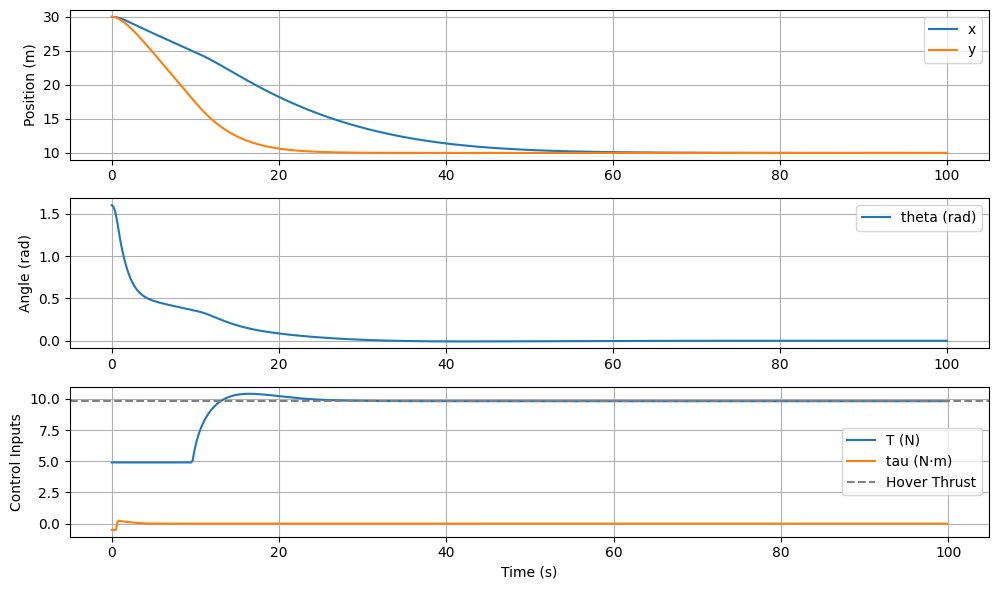

In [7]:
# === Linearization and LQR ===
N = 6
M = 2
A, B, c = linearize(x_fixed, u_fixed) 

x_target = np.array([[10.0], [10.0], [0.0], [0.0], [0.0], [0.0]])
# BEST weight overall: Q = np.diag([1.0, 1.0, 80.0, 1.0, 1.0, 80.0])
Q = np.diag([1.0, 1.0, 80.0, 5.0, 1.0, 80.0])
Q_N = np.copy(Q)
R = np.diag([0.1, 0.1])
P, K = lqr(np.array(A), np.array(B), Q, Q_N, R)

xs, us = simulate_lqr(x_target, u_fixed, K, dt)
# === Plot results ===
t = np.linspace(0, 100.0, len(xs))
plt.figure(figsize=(10,6))
plt.subplot(3,1,1)
plt.plot(t, xs[:,0], label='x')
plt.plot(t, xs[:,1], label='y')
plt.ylabel('Position (m)')
plt.legend(); plt.grid()

plt.subplot(3,1,2)
plt.plot(t, xs[:,2], label='theta (rad)')
plt.ylabel('Angle (rad)')
plt.legend(); plt.grid()

plt.subplot(3,1,3)
plt.plot(t[:-1], us[:,0], label='T (N)')
plt.plot(t[:-1], us[:,1], label='tau (N·m)')
plt.axhline(u_fixed[0,0], color='gray', linestyle='--', label='Hover Thrust')
plt.ylabel('Control Inputs')
plt.xlabel('Time (s)')
plt.legend(); plt.grid()

plt.tight_layout()
plt.show()

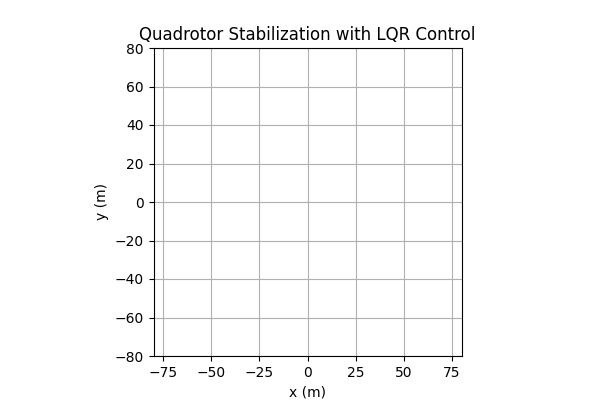

In [8]:
# =====================================================
# 5. ANIMATION
# =====================================================
from matplotlib.animation import FuncAnimation

%matplotlib widget

fig, ax = plt.subplots(figsize=(6, 4))
ax.set_xlim(-80, 80)
ax.set_ylim(-80, 80)
ax.set_aspect('equal')
ax.set_title("Quadrotor Stabilization with LQR Control")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")

# Quadrotor body
body, = ax.plot([], [], 'k-', lw=4)
center, = ax.plot([], [], 'ro', markersize=10)
time_text = ax.text(40, 70, '', fontsize=10)
force_arrow = ax.arrow(0, 0, 0, 0, color='blue')  

L = 20.0  # arm length

def init():
    body.set_data([], [])
    center.set_data([], [])
    time_text.set_text('')
    return body, center, time_text

def update(frame):
    x_pos, y_pos, theta = xs[frame, 0], xs[frame, 1], xs[frame, 2]

    # Compute rotor arm positions
    x1 = x_pos - (L/2) * np.cos(theta)
    x2 = x_pos + (L/2) * np.cos(theta)
    y1 = y_pos - (L/2) * np.sin(theta)
    y2 = y_pos + (L/2) * np.sin(theta)

    body.set_data([x1, x2], [y1, y2])
    center.set_data([x_pos], [y_pos])
    time_text.set_text(f't = {frame*dt:.2f} s')

    return body, center, time_text

frames = range(0, len(xs), 2)   # show every 2nd frame
ani = FuncAnimation(fig, update, frames=frames, init_func=init, blit=False, interval=50)

plt.grid(True)
plt.show()